# 02 · Bayesian analysis of the raw asymmetry $A_{\rm raw}$ in $B^\pm\to K^\pm K^+K^-$

**What this notebook is.** The same data and the **same likelihood** as in notebook 01, analysed with Bayes'
theorem: a prior times the likelihood gives the posterior of $A_{\rm raw}$, sampled with MCMC (`emcee`). The
question of the study is *to what extent a frequentist and a Bayesian analysis give consistent, well-controlled
estimates of $A_{\rm raw}$*; since the model is common, any difference comes from the inference.

**Scale.** As in notebook 01 this is a guided tour of the method, not the production run: chains and toy samples
are shorter than in the report (**report:** values are printed next to ours), so numbers can differ in the last digit.

### Map of the notebook

| § | Content | Report (short → cut appendix) |
|---|---|---|
| 1 | Data; prior, likelihood, posterior | *Bayesian analysis* |
| 2 | MCMC, convergence diagnostics | *Bayesian analysis*; App. *Sampling* |
| 3 | Posterior, credible intervals, HPD | *Posterior results* |
| 4 | Bayes factors (Savage–Dickey), dependence on the prior | *Bayes factors*; App. *Priors* |
| 5 | Systematic uncertainty: 13 variants | *Result and systematics* |
| 6 | Toy experiments: coverage of the credible interval | *Validation*; App. *Toy-MC coverage* |
| 7 | Model adequacy: posterior predictive check [EXTRA] | App. *Model adequacy* |
| 8 | Magnet polarities and sequential update; Dalitz region and veto | *Dalitz*; App. *Robustness* |
| 9 | Comparison with the frequentist profile likelihood | *Discussion* |
| 10 | Low statistics: Bayesian against frequentist intervals | App. *Low statistics* |

Parts that go beyond the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot, emcee, corner
from scipy.special import ndtr
from scipy.stats import norm, chi2, crystalball, gaussian_kde
from iminuit import Minuit

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
np.random.seed(42)

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data, prior, likelihood and posterior

### 1.1 Data
Same preselection and window as in notebook 01 (all three tracks kaon-like and not muons), here in compact form.
We keep the candidates with the weaker PID cut of the variants ($\texttt{ProbK}>0.4$, $\texttt{ProbPi}<0.6$) and
store the weakest PID value of each candidate, so that variants only re-apply tighter cuts.

In [2]:
tracks = (1, 2, 3)
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]
frames = []
for pol in ("Down", "Up"):
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.4) & (df[f"H{i}_ProbPi"] < 0.6) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)
d = d[np.abs(d.q) == 1]

def select(lo=LO, hi=HI, k=0.5, pi=0.5, s=None):
    s = d if s is None else s
    return s[(s.m > lo) & (s.m < hi) & (s.min_probk > k) & (s.max_probpi < pi)].reset_index(drop=True)

sample = select()
m_pos, m_neg = sample.m[sample.q > 0].to_numpy(), sample.m[sample.q < 0].to_numpy()
print(f"candidates in the window: {len(sample)} (report 19731);  B+: {len(m_pos)}, B-: {len(m_neg)}")

candidates in the window: 19731 (report 19731);  B+: 10292, B-: 9439


### 1.2 The model, written as log-prior, log-likelihood and log-posterior

The model is that of notebook 01: for each charge a Gaussian signal (mean $\mu$ and width $\sigma$ shared) and a
double-exponential background (own shape and yield), $N_s^\pm=\frac{N_s}{2}(1\mp A)$,
$N_b^\pm=\frac{N_b}{2}(1\mp A_b)$. Twelve parameters
$\theta=(N_s,N_b,A,A_b,\mu,\sigma,\lambda_1^\pm,\lambda_2^\pm,f_\pm)$.

* **Prior** $\pi(\theta)$: independent and **uniform** on the ranges below (constant in the allowed region, zero
  outside); $\lambda_1>\lambda_2$ removes the label-switching symmetry of the two exponentials. With flat priors the
  posterior is proportional to the likelihood inside the allowed region.
* **Likelihood**: the extended unbinned likelihood of notebook 01.
* **Posterior**: $\ln p(\theta|D)=\ln\mathcal L(D|\theta)+\ln\pi(\theta)$ + const. The evidence $p(D)$ is a constant
  that the MCMC does not need.

In [3]:
names = ["N_s", "N_b", "A", "A_b", "mu", "sigma", "lam1_pos", "lam2_pos", "f_pos", "lam1_neg", "lam2_neg", "f_neg"]
N = len(sample)
PRIOR = {"N_s": (0, 5 * N), "N_b": (0, 5 * N), "A": (-1, 1), "A_b": (-1, 1), "mu": (5260, 5310), "sigma": (3, 40),
         "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
         "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    z = (m - mu) / sigma
    return np.exp(-0.5 * z * z) / (sigma * np.sqrt(2 * np.pi)) / (ndtr((hi - mu) / sigma) - ndtr((lo - mu) / sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

def log_prior(theta):
    v = dict(zip(names, theta))
    for k in names:
        if not PRIOR[k][0] < v[k] < PRIOR[k][1]:
            return -np.inf
    if v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]:      # ordering of the two exponentials
        return -np.inf
    return 0.0                                                               # uniform: a constant

def log_likelihood(theta, m_p, m_n):
    v = dict(zip(names, theta))
    Ns_p, Ns_n = v["N_s"] * (1 - v["A"]) / 2, v["N_s"] * (1 + v["A"]) / 2
    Nb_p, Nb_n = v["N_b"] * (1 - v["A_b"]) / 2, v["N_b"] * (1 + v["A_b"]) / 2
    dens_p = Ns_p * gauss_pdf(m_p, v["mu"], v["sigma"]) + Nb_p * bkg_pdf(m_p, v["lam1_pos"], v["lam2_pos"], v["f_pos"])
    dens_n = Ns_n * gauss_pdf(m_n, v["mu"], v["sigma"]) + Nb_n * bkg_pdf(m_n, v["lam1_neg"], v["lam2_neg"], v["f_neg"])
    return np.sum(np.log(dens_p)) + np.sum(np.log(dens_n)) - (v["N_s"] + v["N_b"])    # extended: -(N_s + N_b)

def log_posterior(theta, m_p=m_pos, m_n=m_neg):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta, m_p, m_n)
    return lp + ll if np.isfinite(ll) else -np.inf

### 1.3 Starting point: the maximum of the posterior

With flat priors the maximum of the posterior (MAP) is the maximum-likelihood estimate: we find it with `Migrad`
and use it to start the walkers close to the bulk.

In [4]:
theta0 = dict(N_s=0.78 * N, N_b=0.22 * N, A=-0.04, A_b=0.0, mu=5284.0, sigma=18.0,
              lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)

def neg2logp(*theta):
    lp = log_posterior(np.array(theta))
    return -2 * lp if np.isfinite(lp) else 1e10

mmap = Minuit(neg2logp, *[theta0[k] for k in names], name=names)
for k in names:
    mmap.limits[k] = PRIOR[k]
mmap.migrad()
theta_map = np.array(mmap.values)
print(f"MAP: A = {mmap.values['A']:+.4f},  N_s = {mmap.values['N_s']:.0f},  mu = {mmap.values['mu']:.2f},  "
      f"sigma = {mmap.values['sigma']:.2f}   (valid: {mmap.valid})")
t0 = time.time(); [log_posterior(theta_map) for _ in range(200)]
print(f"time per log-posterior call: {(time.time() - t0) / 200 * 1e3:.2f} ms")

MAP: A = -0.0441,  N_s = 15328,  mu = 5284.38,  sigma = 18.00   (valid: True)
time per log-posterior call: 0.52 ms


## 2 · Sampling the posterior with MCMC

`emcee` runs an *ensemble* of walkers (affine-invariant sampler of Goodman and Weare), which needs no tuning of the
proposal and works on correlated posteriors. We start 32 walkers in a small ball around the MAP, discard the first
steps as **burn-in** and keep the rest as samples of the posterior.

*Report:* 25 000 steps. Here 12 000, enough for a clear picture; the diagnostics below quantify how good it is.

In [5]:
NWALKERS, NSTEPS, BURN = 32, 12000, 2000
ndim = len(names)
p0 = theta_map + 1e-3 * np.abs(theta_map) * np.random.randn(NWALKERS, ndim)
for k in ("A", "A_b"):                                   # A and A_b are close to zero: use an absolute spread
    p0[:, names.index(k)] = theta_map[names.index(k)] + 1e-3 * np.random.randn(NWALKERS)

sampler = emcee.EnsembleSampler(NWALKERS, ndim, log_posterior)
t0 = time.time()
sampler.run_mcmc(p0, NSTEPS, progress=False)
print(f"MCMC: {NWALKERS} walkers x {NSTEPS} steps in {time.time() - t0:.0f} s")

chain = sampler.get_chain(discard=BURN, flat=True)             # (walkers * (steps - burn), 12) samples of the posterior
tau = sampler.get_autocorr_time(discard=BURN, quiet=True)
print(f"samples: {chain.shape[0]};  acceptance fraction: {sampler.acceptance_fraction.mean():.2f}   (report: 0.38)")
print(f"integrated autocorrelation time: {tau.min():.0f} - {tau.max():.0f} steps   (report: 147 - 183)")
print(f"chain length / tau = {(NSTEPS - BURN) / tau.max():.0f}   (rule of thumb: > 50;  report 113)")

MCMC: 32 walkers x 12000 steps in 229 s


samples: 320000;  acceptance fraction: 0.38   (report: 0.38)
integrated autocorrelation time: 130 - 161 steps   (report: 147 - 183)
chain length / tau = 62   (rule of thumb: > 50;  report 113)


### 2.1 Convergence: trace plot from a dispersed start

A chain started near the maximum could hide a second mode. We start 32 walkers **uniformly over the whole prior
box** and check that they all end in the same place (the dotted line marks half of the chain).

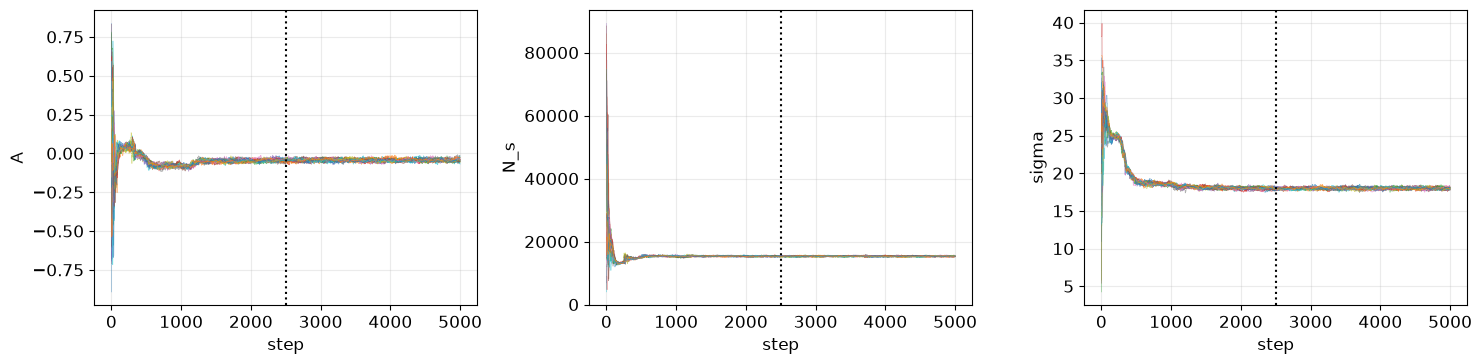

dispersed start: A = -0.0441 (report: -0.0446, -0.0442);  walkers in the bulk: 32/32


In [6]:
rng = np.random.default_rng(7)
lo_box = np.array([PRIOR[k][0] for k in names]); hi_box = np.array([PRIOR[k][1] for k in names])
p_disp = lo_box + (hi_box - lo_box) * rng.uniform(0.02, 0.98, (NWALKERS, ndim))
for w in range(NWALKERS):                                 # every walker must start where the posterior is non-zero
    while not np.isfinite(log_posterior(p_disp[w])):
        p_disp[w] = lo_box + (hi_box - lo_box) * rng.uniform(0.02, 0.98, ndim)
N_DISP = 5000
samp_d = emcee.EnsembleSampler(NWALKERS, ndim, log_posterior)
samp_d.run_mcmc(p_disp, N_DISP, progress=False)
tr = samp_d.get_chain()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, k in zip(ax, ("A", "N_s", "sigma")):
    a.plot(tr[:, :, names.index(k)], lw=0.4, alpha=0.6)
    a.axvline(N_DISP // 2, color="k", ls=":"); a.set(xlabel="step", ylabel=k)
plt.tight_layout(); plt.show()
A_disp = samp_d.get_chain(discard=N_DISP // 2, flat=True)[:, names.index("A")]
print(f"dispersed start: A = {np.median(A_disp):+.4f} (report: -0.0446, -0.0442);  "
      f"walkers in the bulk: {np.sum(samp_d.get_log_prob()[-1] > log_posterior(theta_map) - 20)}/{NWALKERS}")

### 2.2 An independent sampler: Metropolis–Hastings written by hand [EXTRA]

To see what `emcee` does and to check the implementation we write the simplest MCMC: from $\theta$ propose
$\theta'=\theta+\text{(Gaussian step)}$ and accept it with probability $\min(1,p(\theta')/p(\theta))$, so that the
chain satisfies detailed balance with the posterior as stationary distribution. The covariance of the step is that
of the `emcee` posterior scaled by $2.38^2/d$ (optimal for a Gaussian target).

In [7]:
def metropolis_hastings(logp, x0, cov, n_steps):
    d_ = len(x0)
    L = np.linalg.cholesky(cov * 2.38**2 / d_)
    x, lp = x0.copy(), logp(x0)
    out, n_acc = np.empty((n_steps, d_)), 0
    for i in range(n_steps):
        y = x + L @ np.random.randn(d_)                   # proposal
        lp_y = logp(y)
        if np.log(np.random.uniform()) < lp_y - lp:       # accept with probability min(1, ratio)
            x, lp, n_acc = y, lp_y, n_acc + 1
        out[i] = x
    return out, n_acc / n_steps

t0 = time.time()
mh, acc = metropolis_hastings(log_posterior, theta_map, np.cov(chain.T), 60000)
mh = mh[10000:]
A_mh = mh[:, names.index("A")]
print(f"Metropolis-Hastings: {time.time() - t0:.0f} s, acceptance {acc:.2f}")
print(f"  A = {np.median(A_mh):+.4f} +- {A_mh.std():.4f}      emcee: A = {np.median(chain[:, 2]):+.4f} +- {chain[:, 2].std():.4f}")

Metropolis-Hastings: 35 s, acceptance 0.24
  A = -0.0440 +- 0.0084      emcee: A = -0.0446 +- 0.0087


## 3 · Posterior of $A_{\rm raw}$ and credible intervals

The marginal posterior of $A$ is the histogram of the $A$ component of the chain (the other 11 parameters are
*marginalised*: this is what the Bayesian analysis does where the frequentist one *profiles*). We quote the median
and the equal-tailed 68 %/95 % **credible intervals** (percentiles), and the **highest posterior density** (HPD)
interval, the shortest interval with 68 % probability.

A_raw = -0.0446   68% CI [-0.0532, -0.0357]   95% CI [-0.0615, -0.0274]   sd 0.0087
  report: -0.0443, [-0.0528, -0.0358], [-0.0608, -0.0276], sd 0.0085
HPD 68%: [-0.0531, -0.0357]   (report: [-0.0525, -0.0355])
A_b = -0.040 +- 0.018   (report: -0.040 +- 0.018);  N_s = 15334 +- 130  (report: 15328 +- 133)


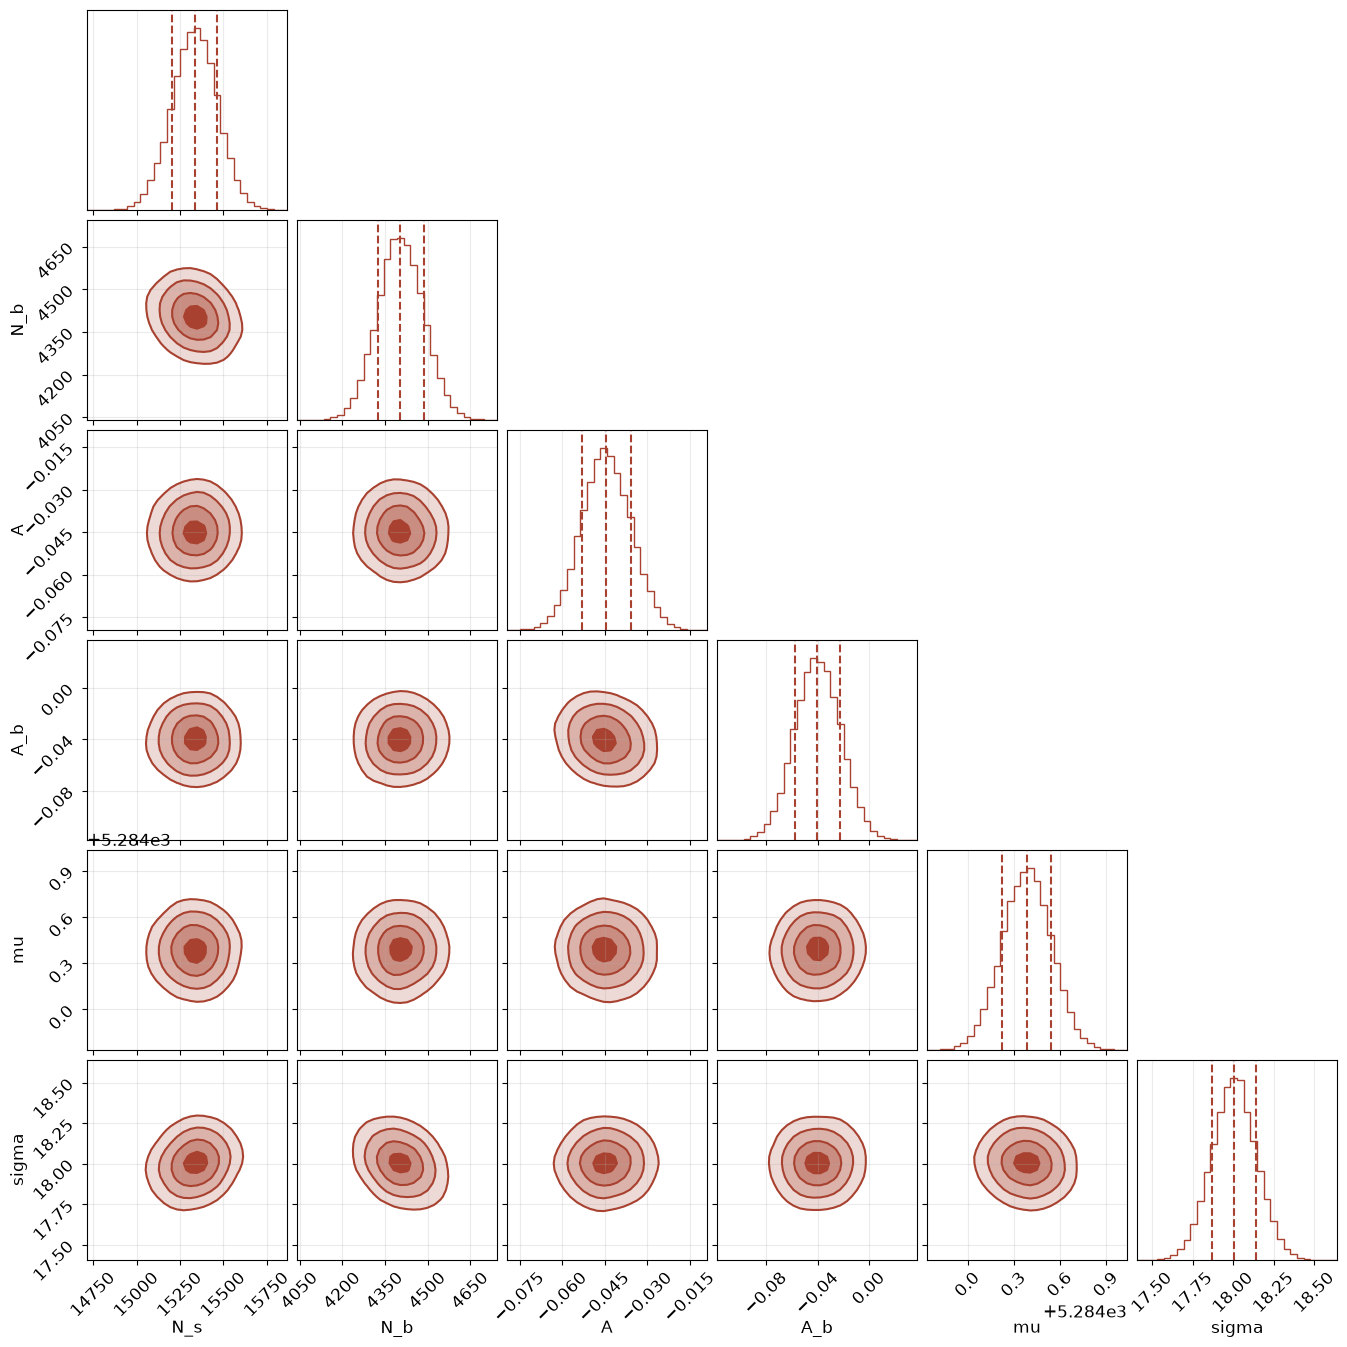

In [8]:
A_s, Ab_s = chain[:, names.index("A")], chain[:, names.index("A_b")]

def hpd(x, p=0.6827):
    s = np.sort(x); k = int(np.ceil(p * len(s)))
    j = np.argmin(s[k:] - s[:len(s) - k])
    return s[j], s[j + k]

q16, q50, q84 = np.percentile(A_s, [15.865, 50, 84.135])
q025, q975 = np.percentile(A_s, [2.5, 97.5])
print(f"A_raw = {q50:+.4f}   68% CI [{q16:+.4f}, {q84:+.4f}]   95% CI [{q025:+.4f}, {q975:+.4f}]   sd {A_s.std():.4f}")
print("  report: -0.0443, [-0.0528, -0.0358], [-0.0608, -0.0276], sd 0.0085")
print(f"HPD 68%: [{hpd(A_s)[0]:+.4f}, {hpd(A_s)[1]:+.4f}]   (report: [-0.0525, -0.0355])")
print(f"A_b = {np.median(Ab_s):+.3f} +- {Ab_s.std():.3f}   (report: -0.040 +- 0.018);  "
      f"N_s = {np.median(chain[:, 0]):.0f} +- {chain[:, 0].std():.0f}  (report: 15328 +- 133)")

main = ["N_s", "N_b", "A", "A_b", "mu", "sigma"]
fig = corner.corner(chain[:, [names.index(k) for k in main]], labels=main, quantiles=[0.16, 0.5, 0.84],
                    color=C["bayes"], plot_datapoints=False, fill_contours=True, bins=30, smooth=1.0)
plt.show()

Two remarks. (i) $A$ is almost uncorrelated with the other parameters, which is why marginalising (Bayesian) and
profiling (frequentist) the nuisance parameters give the same answer. (ii) The largest correlation is with $A_b$:
if the background were symmetric ($A_b=0$) $A$ would move accordingly, which is one of the systematic variants.
[EXTRA] The *conditional* posterior of $A$ at $A_b=0$ for a Gaussian posterior has mean
$\bar A+\rho\,\sigma_A/\sigma_{A_b}\,(0-\bar A_b)$:

In [9]:
cov = np.cov(A_s, Ab_s)
rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
A_cond = A_s.mean() + cov[0, 1] / cov[1, 1] * (0 - Ab_s.mean())
print(f"corr(A, A_b) = {rho:+.2f} (report: -0.17);  A given A_b = 0: {A_cond:+.4f}   (report: -0.0475; fit with A_b = 0: -0.0471)")

corr(A, A_b) = -0.17 (report: -0.17);  A given A_b = 0: -0.0478   (report: -0.0475; fit with A_b = 0: -0.0471)


## 4 · Bayes factors and dependence on the prior

The Bayes factor compares two hypotheses through their **evidences**,
$BF_{10}=P(D|H_1)/P(D|H_0)$, with $H_0:A=0$ and $H_1:A$ free with a uniform prior on $(-1,1)$.

**Evidence by direct integration** (the method of the course). $P(D|H_1)=\int\mathcal L\,\pi\,dA$; as a
simplification we fix the nuisance parameters at the MAP (a grid in $A$ only), so this is a *conditional* Bayes factor.

**Savage–Dickey ratio** [EXTRA]. For nested hypotheses and shared priors on the nuisance parameters,
$BF_{01}=p(A=0|D)/\pi(A=0)$: no integral over the 12 parameters. $A=0$ is $5\sigma$ from the median, where the
chain has no samples, so $p(A=0|D)$ is taken from the Gaussian approximation of the posterior.

In [10]:
# (a) evidence by direct integration over A, nuisance parameters fixed at the MAP
A_grid = np.linspace(-0.2, 0.2, 801)
ll = np.array([log_likelihood(np.where(np.arange(ndim) == 2, a, theta_map), m_pos, m_neg) for a in A_grid])
L = np.exp(ll - ll.max())
Z1 = np.trapezoid(L * 0.5, A_grid)                       # prior density 1/2 on (-1, 1)
L0 = np.exp(log_likelihood(np.where(np.arange(ndim) == 2, 0.0, theta_map), m_pos, m_neg) - ll.max())
print(f"evidence by integration (grid):  BF_01 = {L0 / Z1:.2e}")

# (b) Savage-Dickey with the Gaussian approximation of the marginal posterior
def savage_dickey(x, prior_density):
    return norm.pdf(0.0, x.mean(), x.std()) / prior_density

bf_A, bf_Ab = savage_dickey(A_s, 0.5), savage_dickey(Ab_s, 0.5)
print(f"Savage-Dickey, A = 0:   BF_01 = {bf_A:.2e}, BF_10 = {1 / bf_A:.1e}     (report: 1.1e-4, 9e3; decisive on Jeffreys' scale)")
print(f"Savage-Dickey, A_b = 0: BF_01 = {bf_Ab:.2f}, BF_10 = {1 / bf_Ab:.2f}     (report: BF_01 = 3.5)")

evidence by integration (grid):  BF_01 = 7.02e-05
Savage-Dickey, A = 0:   BF_01 = 1.75e-04, BF_10 = 5.7e+03     (report: 1.1e-4, 9e3; decisive on Jeffreys' scale)
Savage-Dickey, A_b = 0: BF_01 = 3.52, BF_10 = 0.28     (report: BF_01 = 3.5)


**The Ockham factor.** $A_b$ is $2.3\sigma$ from zero and yet $BF_{01}(A_b=0)>1$: the likelihood gain does not
compensate for spreading the prior over $(-1,1)$. The Bayes factor *depends on the prior width* $W$
($BF_{01}=p(0|D)\cdot2W$ for a uniform prior on $(-W,W)$), whereas the posterior of $A$ does not.

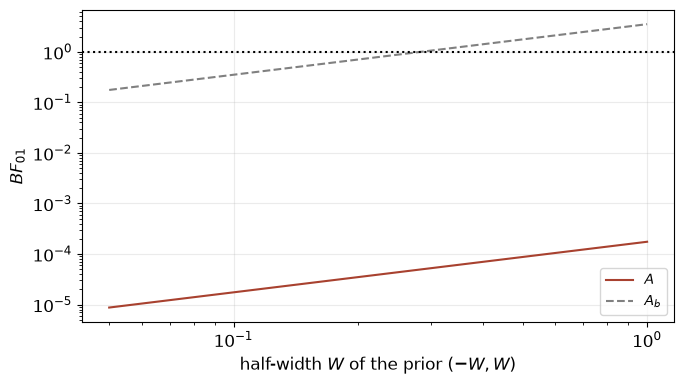

BF_01(A = 0) with A in (-0.3, 0.3): 5.3e-05   (drops by a factor 3.3; report: factor 3.3, the conclusion is unchanged)


In [11]:
W = np.geomspace(0.05, 1.0, 40)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(W, norm.pdf(0, A_s.mean(), A_s.std()) * 2 * W, color=C["bayes"], label="$A$")
ax.plot(W, norm.pdf(0, Ab_s.mean(), Ab_s.std()) * 2 * W, color="gray", ls="--", label="$A_b$")
ax.axhline(1, color="k", ls=":"); ax.set(xscale="log", yscale="log", xlabel="half-width $W$ of the prior $(-W,W)$", ylabel="$BF_{01}$")
ax.legend(); plt.tight_layout(); plt.show()
bf_narrow = norm.pdf(0, A_s.mean(), A_s.std()) * 0.6
print(f"BF_01(A = 0) with A in (-0.3, 0.3): {bf_narrow:.1e}   "
      f"(drops by a factor {bf_A / bf_narrow:.1f}; report: factor 3.3, the conclusion is unchanged)")

**Dependence of the posterior on the prior** [EXTRA]. We can obtain the posterior under *another* prior without a new
MCMC by **reweighting** the chain with $\pi'(\theta)/\pi(\theta)$. For example, log-uniform priors on the yields or on
the slopes (scale-invariant), or a flat prior on $(N_s^+,N_s^-)$ instead of $(N_s,A)$ (Jacobian $N_s$). The effective
sample size $1/\sum w^2$ tells how reliable each reweighting is.

In [12]:
col = lambda k: chain[:, names.index(k)]
lam = np.vstack([col(k) for k in ("lam1_pos", "lam2_pos", "lam1_neg", "lam2_neg")])
alt_priors = {"nominal (uniform)": np.ones(len(chain)),
              "log-uniform N_s, N_b": 1 / (col("N_s") * col("N_b")),
              "log-uniform slopes": 1 / lam.prod(axis=0),
              "flat in (N_s+, N_s-)": col("N_s")}

def wquantile(x, w, q):
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return x[o][np.searchsorted(c, q)]

print(f"{'prior':26s} {'median A':>9s}  {'68% interval':>20s}   ESS")
for lab, w in alt_priors.items():
    w = w / w.sum()
    print(f"{lab:26s} {wquantile(A_s, w, 0.5):+9.4f}  [{wquantile(A_s, w, 0.1587):+.4f}, {wquantile(A_s, w, 0.8413):+.4f}]  {1 / np.sum(w**2):7.0f}")
print("report: all medians -0.0440 ... -0.0444, intervals unchanged to 0.0002")

prior                       median A          68% interval   ESS
nominal (uniform)            -0.0446  [-0.0532, -0.0357]   320000


log-uniform N_s, N_b         -0.0446  [-0.0532, -0.0357]   319890
log-uniform slopes           -0.0444  [-0.0530, -0.0354]   136080


flat in (N_s+, N_s-)         -0.0446  [-0.0532, -0.0357]   319977
report: all medians -0.0440 ... -0.0444, intervals unchanged to 0.0002


## 5 · Systematic uncertainty: the same 13 variants, Bayesian fits

The variants and the combination rule are those of notebook 01 (window, background, signal, preselection; Barlow
criterion $\sigma_B$ for the variants that change the sample [EXTRA], rejection of variants that the data reject,
largest shift of each group, groups in quadrature). Each variant is a new MCMC fit. To vary the model without
writing 13 posteriors, `make_logpost` builds the log-posterior from the same options as in notebook 01; with the
default options it is the nominal posterior (checked below).

In [13]:
def make_logpost(m_p, m_n, lo=LO, hi=HI, n_exp=2, shared_shape=False, sym_bkg=False, signal="gauss", per_charge=False):
    """Log-posterior (uniform priors) of a variant of the model. Returns names, logpost, density(v, side, m)."""
    N_ = len(m_p) + len(m_n)
    nm = ["N_s", "N_b", "A"] + ([] if sym_bkg else ["A_b"])
    nm += ["mu_pos", "sigma_pos", "mu_neg", "sigma_neg"] if per_charge else ["mu", "sigma"]
    if signal == "cb":
        nm += ["beta", "m_cb"]
    for s in (["all"] if shared_shape else ["pos", "neg"]):
        nm += [f"lam1_{s}"] + ([f"lam2_{s}", f"f_{s}"] if n_exp == 2 else [])

    bounds = {}
    for k in nm:
        if k.startswith("N_"): bounds[k] = (0, 5 * N_)
        elif k in ("A", "A_b"): bounds[k] = (-1, 1)
        elif k.startswith("mu"): bounds[k] = (5260, 5310)
        elif k.startswith("sigma"): bounds[k] = (3, 40)
        elif k == "beta": bounds[k] = (0.3, 5)
        elif k == "m_cb": bounds[k] = (1.01, 50)
        elif k.startswith("f_"): bounds[k] = (0, 1)
        else: bounds[k] = (1e-5, 0.1)               # slopes

    def density(v, side, m):
        sign = -1 if side == "pos" else +1
        n_sig = v["N_s"] * (1 + sign * v["A"]) / 2
        a_b = 0.0 if sym_bkg else v["A_b"]
        n_bkg = v["N_b"] * (1 + sign * a_b) / 2
        mu, sg = (v[f"mu_{side}"], v[f"sigma_{side}"]) if per_charge else (v["mu"], v["sigma"])
        if signal == "gauss":
            sig = gauss_pdf(m, mu, sg, lo, hi)
        else:
            z = crystalball.cdf((hi - mu) / sg, v["beta"], v["m_cb"]) - crystalball.cdf((lo - mu) / sg, v["beta"], v["m_cb"])
            sig = crystalball.pdf((m - mu) / sg, v["beta"], v["m_cb"]) / sg / z
        s_ = "all" if shared_shape else side
        if n_exp == 2:
            bkg = bkg_pdf(m, v[f"lam1_{s_}"], v[f"lam2_{s_}"], v[f"f_{s_}"], lo, hi)
        else:
            bkg = exp_pdf(m, v[f"lam1_{s_}"], lo, hi)
        return n_sig * sig + n_bkg * bkg

    def logpost(theta):
        v = dict(zip(nm, theta))
        for k in nm:
            if not bounds[k][0] < v[k] < bounds[k][1]:
                return -np.inf
        for s in (["all"] if shared_shape else ["pos", "neg"]):
            if n_exp == 2 and v[f"lam1_{s}"] <= v[f"lam2_{s}"]:
                return -np.inf
        dp, dn = density(v, "pos", m_p), density(v, "neg", m_n)
        if np.any(dp <= 0) or np.any(dn <= 0):
            return -np.inf
        n_tot = v["N_s"] + v["N_b"]
        return np.sum(np.log(dp)) + np.sum(np.log(dn)) - n_tot

    start = {"N_s": 0.78 * N_, "N_b": 0.22 * N_, "A": -0.04, "A_b": 0.0, "mu": 5284.0, "sigma": 18.0,
             "mu_pos": 5284.0, "mu_neg": 5284.0, "sigma_pos": 18.0, "sigma_neg": 18.0, "beta": 1.8, "m_cb": 10.0}
    for k in nm:
        if k.startswith("lam1"): start[k] = 0.03 if n_exp == 2 else 0.004
        if k.startswith("lam2"): start[k] = 0.002
        if k.startswith("f_"): start[k] = 0.15
    return nm, logpost, density, start, bounds

nm_chk, lp_chk, _, _, _ = make_logpost(m_pos, m_neg)
assert abs(lp_chk(theta_map[[names.index(k) for k in nm_chk]]) - log_posterior(theta_map)) < 1e-6
print("make_logpost with default options = nominal posterior: OK")

make_logpost with default options = nominal posterior: OK


In [14]:
def bayes_fit(s, nsteps=2000, burn=400, nwalkers=None, start_from=None, **opts):
    """MAP with Migrad, then emcee. Returns names, chain (flat), MAP, and a function logpost."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    nm, lp, density, st, bounds = make_logpost(mp, mn, **opts)
    st = {**st, **(start_from or {})}
    def f(*theta):
        v = lp(np.array(theta))
        return -2 * v if np.isfinite(v) else 1e10
    mm = Minuit(f, *[st[k] for k in nm], name=nm)
    for k in nm:
        mm.limits[k] = bounds[k]
    mm.migrad()
    x_map = np.array(mm.values)
    nw = nwalkers or max(2 * len(nm) + 2, 24)
    p0 = x_map + 1e-3 * np.abs(x_map) * np.random.randn(nw, len(nm))
    for k in ("A", "A_b"):
        if k in nm: p0[:, nm.index(k)] = x_map[nm.index(k)] + 1e-3 * np.random.randn(nw)
    for w in range(nw):
        while not np.isfinite(lp(p0[w])):
            p0[w] = x_map + 1e-4 * np.abs(x_map) * np.random.randn(len(nm))
    samp = emcee.EnsembleSampler(nw, len(nm), lp)
    samp.run_mcmc(p0, nsteps, progress=False)
    ch = samp.get_chain(discard=burn, flat=True)
    return dict(names=nm, chain=ch, map=x_map, logpost=lp, density=density, minuit=mm,
                A=np.median(ch[:, nm.index("A")]), sd=ch[:, nm.index("A")].std(),
                ci68=np.percentile(ch[:, nm.index("A")], [15.865, 84.135]), n=len(s))

def binned_chi2_bayes(res, s, lo=LO, hi=HI, width=10.0):
    """Pearson chi2 (10 MeV bins, both charges) at the posterior median."""
    v = dict(zip(res["names"], np.median(res["chain"], axis=0)))
    edges = np.arange(lo, hi + 1e-9, width)
    sub = (np.arange(5) + 0.5) / 5
    pts = edges[:-1, None] + sub[None, :] * width
    chi2_ = 0.0
    for side, mask in (("pos", s.q > 0), ("neg", s.q < 0)):
        nu = res["density"](v, side, pts).mean(axis=1) * width
        obs = np.histogram(s.m[mask], edges)[0]
        chi2_ += np.sum((obs - nu)**2 / nu)
    return chi2_

In [15]:
VARIANTS = {   # name: (group, selection options, model options)
    "window_lo5050":       ("window", dict(lo=5050.0), dict(lo=5050.0)),
    "window_lo5150":       ("window", dict(lo=5150.0), dict(lo=5150.0)),
    "window_hi5450":       ("window", dict(hi=5450.0), dict(hi=5450.0)),
    "window_hi5700":       ("window", dict(hi=5700.0), dict(hi=5700.0)),
    "bkg_single_exp":      ("background", {}, dict(n_exp=1)),
    "bkg_shared_shape":    ("background", {}, dict(shared_shape=True)),
    "bkg_symmetric":       ("background", {}, dict(sym_bkg=True)),
    "signal_crystal_ball": ("signal", {}, dict(signal="cb")),
    "signal_per_charge":   ("signal", {}, dict(per_charge=True)),
    "presel_probk_0.4":    ("preselection", dict(k=0.4), {}),
    "presel_probk_0.6":    ("preselection", dict(k=0.6), {}),
    "presel_probpi_0.4":   ("preselection", dict(pi=0.4), {}),
    "presel_probpi_0.6":   ("preselection", dict(pi=0.6), {}),
}
REPORT_A = {"window_lo5050": -0.0446, "window_lo5150": -0.0444, "window_hi5450": -0.0440, "window_hi5700": -0.0456,
            "bkg_single_exp": -0.0480, "bkg_shared_shape": -0.0480, "bkg_symmetric": -0.0471,
            "signal_crystal_ball": -0.0445, "signal_per_charge": -0.0443,
            "presel_probk_0.4": -0.0474, "presel_probk_0.6": -0.0385, "presel_probpi_0.4": -0.0421, "presel_probpi_0.6": -0.0446}
SAMPLE_CHANGING = ("window", "preselection")

t0 = time.time()
nominal = dict(A=np.median(A_s), sd=A_s.std())
chi2_nom = binned_chi2_bayes(dict(names=names, chain=chain, density=lambda v, side, m: (
    (v["N_s"] * (1 + (-1 if side == 'pos' else 1) * v["A"]) / 2) * gauss_pdf(m, v["mu"], v["sigma"])
    + (v["N_b"] * (1 + (-1 if side == 'pos' else 1) * v["A_b"]) / 2) * bkg_pdf(m, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))), sample)
rows = []
for name, (group, sel_opt, mod_opt) in VARIANTS.items():
    s = select(**sel_opt)
    r = bayes_fit(s, **mod_opt)
    changes = group in SAMPLE_CHANGING
    shift = r["A"] - nominal["A"]
    sigma_B = np.sqrt(abs(r["sd"]**2 - nominal["sd"]**2)) if changes else np.nan
    rejected = (not changes) and (binned_chi2_bayes(r, s, **{k: v for k, v in mod_opt.items() if k in ("lo", "hi")}) - chi2_nom > 25)
    counts = (not rejected) and ((not changes) or abs(shift) > sigma_B)
    rows.append(dict(variant=name, group=group, n=len(s), A=r["A"], shift=shift, sigma_B=sigma_B,
                     rejected=rejected, counts=counts, report_A=REPORT_A[name]))
syst = pd.DataFrame(rows)
print(f"13 Bayesian fits in {time.time() - t0:.0f} s")
print(syst.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
group_unc = syst[syst.counts].groupby("group")["shift"].apply(lambda x: x.abs().max())
group_unc = group_unc.reindex(["window", "background", "signal", "preselection"]).fillna(0.0)
syst_total = np.sqrt((group_unc**2).sum())
print("\nuncertainty by group:", group_unc.round(4).to_dict())
print(f"total systematic = {syst_total:.4f}   (report: 0.0014, 0.0037, 0.0002, 0.0058 -> 0.0070)")
print(f"\nResult: A_raw = {nominal['A']:+.4f} +- {nominal['sd']:.4f} (stat) +- {syst_total:.4f} (syst)   report: -0.0443 +- 0.0085 +- 0.0070")

13 Bayesian fits in 413 s
            variant        group     n       A   shift  sigma_B  rejected  counts  report_A
      window_lo5050       window 21164 -0.0444 +0.0002  +0.0001     False    True   -0.0446
      window_lo5150       window 18566 -0.0438 +0.0009  +0.0020     False   False   -0.0444
      window_hi5450       window 19004 -0.0446 +0.0001  +0.0028     False   False   -0.0440
      window_hi5700       window 20191 -0.0458 -0.0012  +0.0028     False   False   -0.0456
     bkg_single_exp   background 19731 -0.0486 -0.0040      NaN      True   False   -0.0480
   bkg_shared_shape   background 19731 -0.0489 -0.0042      NaN     False    True   -0.0480
      bkg_symmetric   background 19731 -0.0466 -0.0020      NaN     False    True   -0.0471
signal_crystal_ball       signal 19731 -0.0440 +0.0007      NaN     False    True   -0.0445
  signal_per_charge       signal 19731 -0.0443 +0.0003      NaN     False    True   -0.0443
   presel_probk_0.4 preselection 26553 -0.0471 -0.0025

## 6 · Toy experiments: does the 68 % credible interval contain the truth 68 % of the time?

A credible interval is a statement about $A$ given the data and the prior; it need not have frequentist coverage.
With a large sample and flat priors it should (Bernstein–von Mises). We **generate pseudo-experiments from the model**
at the posterior medians (Poisson yields, masses by the transformation method, as in notebook 01), fit each with the
same posterior and count how often the 68 % and 95 % credible intervals contain the injected $A$. The pulls
$(\hat A-A_{\rm true})/\sigma(\hat A)$ must be standard normal.

*Report:* 200 toys, 12 000 steps each. Here 20 toys of 1200 steps, started at the true value (no burn-in needed).

In [16]:
def sample_gauss(mu, sigma, n):
    u = np.random.uniform(norm.cdf(LO, mu, sigma), norm.cdf(HI, mu, sigma), n)
    return mu + sigma * norm.ppf(u)

def sample_exp(lam, n):
    return LO - np.log(1 - np.random.uniform(size=n) * (1 - np.exp(-lam * (HI - LO)))) / lam

def make_toy(v):
    """One pseudo-experiment (m_pos, m_neg) from the parameter dictionary v (nominal model)."""
    out = []
    for side, sign in (("pos", -1), ("neg", +1)):
        n_s = np.random.poisson(v["N_s"] * (1 + sign * v["A"]) / 2)
        n_b = np.random.poisson(v["N_b"] * (1 + sign * v["A_b"]) / 2)
        steep = np.random.uniform(size=n_b) < v[f"f_{side}"]
        bkg = np.where(steep, sample_exp(v[f"lam1_{side}"], n_b), sample_exp(v[f"lam2_{side}"], n_b))
        out.append(np.concatenate([sample_gauss(v["mu"], v["sigma"], n_s), bkg]))
    return out

v_true = dict(zip(names, np.median(chain, axis=0)))
A_true = v_true["A"]
N_TOYS = 20
toy_rows = []
t0 = time.time()
for i in range(N_TOYS):
    mp_t, mn_t = make_toy(v_true)
    toy = pd.DataFrame({"m": np.concatenate([mp_t, mn_t]), "q": np.concatenate([np.ones(len(mp_t)), -np.ones(len(mn_t))])})
    r = bayes_fit(toy, nsteps=1200, burn=250, start_from=v_true)
    lo68, hi68 = r["ci68"]; lo95, hi95 = np.percentile(r["chain"][:, r["names"].index("A")], [2.5, 97.5])
    toy_rows.append(dict(A=r["A"], sd=r["sd"], in68=lo68 < A_true < hi68, in95=lo95 < A_true < hi95))
toys = pd.DataFrame(toy_rows)
pull = (toys.A - A_true) / toys.sd
print(f"{N_TOYS} toys in {time.time() - t0:.0f} s")
print(f"coverage 68%: {toys.in68.mean():.2f} +- {np.sqrt(0.68 * 0.32 / N_TOYS):.2f}   95%: {toys.in95.mean():.2f} +- {np.sqrt(0.95 * 0.05 / N_TOYS):.2f}"
      "      (report: 0.65 +- 0.03, 0.93 +- 0.02)")
print(f"pulls: mean {pull.mean():+.2f}, width {pull.std():.2f}      (report: width 1.04);  bias of the median: {toys.A.mean() - A_true:+.4f}")

20 toys in 322 s
coverage 68%: 0.65 +- 0.10   95%: 0.95 +- 0.05      (report: 0.65 +- 0.03, 0.93 +- 0.02)
pulls: mean +0.38, width 0.90      (report: width 1.04);  bias of the median: +0.0032


## 7 · Does the model describe the data? Posterior predictive check [EXTRA]

The posterior says nothing about whether the *model* is adequate. The **posterior predictive check** simulates
replicas of the whole dataset from parameters drawn from the posterior and compares a discrepancy statistic computed
on the data with its distribution on the replicas; $p_B=P(T^{\rm rep}\ge T^{\rm obs})$.

We use the binned $\chi^2$ (which the fit indirectly optimises, so a weak test) and the counting asymmetry in the
fit window and in the sidebands $|m-\mu|>4\sigma$ (not fitted by the model).

In [17]:
edges10 = np.arange(LO, HI + 1e-9, 10.0)
sub = (np.arange(5) + 0.5) / 5
pts10 = edges10[:-1, None] + sub[None, :] * 10.0

def chi2_binned(m_p, m_n, v):
    c = 0.0
    for side, mm in (("pos", m_p), ("neg", m_n)):
        sign = -1 if side == "pos" else +1
        dens = ((v["N_s"] * (1 + sign * v["A"]) / 2) * gauss_pdf(pts10, v["mu"], v["sigma"])
                + (v["N_b"] * (1 + sign * v["A_b"]) / 2) * bkg_pdf(pts10, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))
        nu = dens.mean(axis=1) * 10.0
        c += np.sum((np.histogram(mm, edges10)[0] - nu)**2 / nu)
    return c

def count_asym(m_p, m_n, sel=lambda m: np.ones_like(m, bool)):
    a, b = np.sum(sel(m_n)), np.sum(sel(m_p))
    return (a - b) / (a + b)

mu_hat, sg_hat = v_true["mu"], v_true["sigma"]
side_sel = lambda m: np.abs(m - mu_hat) > 4 * sg_hat
T_obs, T_rep = [], []
for i in np.random.choice(len(chain), 200, replace=False):
    v = dict(zip(names, chain[i]))
    mp_r, mn_r = make_toy(v)
    T_obs.append([chi2_binned(m_pos, m_neg, v), count_asym(m_pos, m_neg), count_asym(m_pos, m_neg, side_sel)])
    T_rep.append([chi2_binned(mp_r, mn_r, v), count_asym(mp_r, mn_r), count_asym(mp_r, mn_r, side_sel)])
T_obs, T_rep = np.array(T_obs), np.array(T_rep)
for k, lab in enumerate(("chi2 (10 MeV bins)", "A_count, window", "A_count, sidebands")):
    p_b = np.mean(T_rep[:, k] >= T_obs[:, k])
    if k > 0: p_b = 2 * min(p_b, 1 - p_b)
    print(f"{lab:22s} observed {np.median(T_obs[:, k]):9.4f}   replicas {T_rep[:, k].mean():9.4f} +- {T_rep[:, k].std():.4f}   p_B = {p_b:.3f}")
print("report: chi2 p_B < 0.001 (model does not reach chi2/ndof ~ 1), asymmetries reproduced")
print(f"chi2/ndof at the posterior median: {chi2_binned(m_pos, m_neg, v_true):.0f}/88   (report: 164/88)")

chi2 (10 MeV bins)     observed  170.4452   replicas   98.8820 +- 13.8239   p_B = 0.000
A_count, window        observed   -0.0432   replicas   -0.0436 +- 0.0099   p_B = 0.980
A_count, sidebands     observed   -0.0103   replicas   -0.0221 +- 0.0257   p_B = 0.650
report: chi2 p_B < 0.001 (model does not reach chi2/ndof ~ 1), asymmetries reproduced
chi2/ndof at the posterior median: 159/88   (report: 164/88)


## 8 · Robustness: magnet polarities, Dalitz region and charm veto

**Magnet polarities and sequential update.** The two polarities are fitted separately. Bayesian learning is
*sequential*: the posterior of the first sample is the prior of the second, so the product of the two posteriors of $A$
(normalised) must reproduce the posterior of the joint fit if the two samples share the same $A$.

magnet down: n =  11636   A = -0.0497 +- 0.0113


magnet up  : n =   8095   A = -0.0361 +- 0.0136
report: down -0.0497 [-0.0607,-0.0386], up -0.0378 [-0.0507,-0.0251]; difference 0.7 sigma


sequential update (down x up): A = -0.0440 +- 0.0089;   joint fit: -0.0446 +- 0.0087


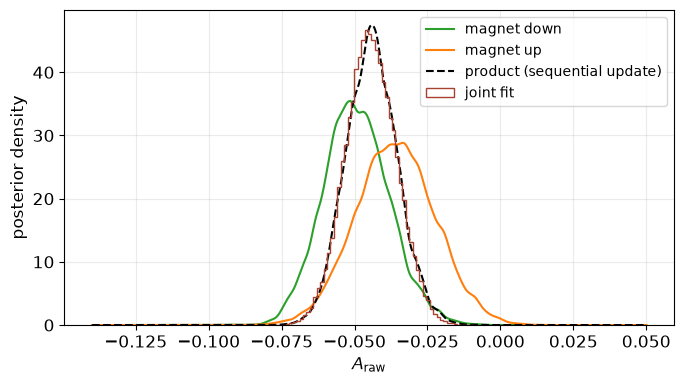

In [18]:
pol_res = {}
for pol in ("down", "up"):
    s = sample[sample.magnet == pol]
    pol_res[pol] = bayes_fit(s, nsteps=2500, burn=500)
    print(f"magnet {pol:4s}: n = {len(s):6d}   A = {pol_res[pol]['A']:+.4f} +- {pol_res[pol]['sd']:.4f}")
print("report: down -0.0497 [-0.0607,-0.0386], up -0.0378 [-0.0507,-0.0251]; difference 0.7 sigma")

xs = np.linspace(-0.14, 0.05, 2000)
dens = [gaussian_kde(pol_res[p]["chain"][:, pol_res[p]["names"].index("A")])(xs) for p in ("down", "up")]
post_seq = dens[0] * dens[1]
post_seq /= np.trapezoid(post_seq, xs)
mean_seq = np.trapezoid(xs * post_seq, xs); sd_seq = np.sqrt(np.trapezoid((xs - mean_seq)**2 * post_seq, xs))
print(f"sequential update (down x up): A = {mean_seq:+.4f} +- {sd_seq:.4f};   joint fit: {np.median(A_s):+.4f} +- {A_s.std():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, dens[0], color=C["down"], label="magnet down"); ax.plot(xs, dens[1], color=C["up"], label="magnet up")
ax.plot(xs, post_seq, "k--", label="product (sequential update)")
ax.hist(A_s, bins=60, density=True, histtype="step", color=C["bayes"], label="joint fit")
ax.set(xlabel="$A_{\\rm raw}$", ylabel="posterior density"); ax.legend(); plt.tight_layout(); plt.show()

**Dalitz region of the published analysis and charm veto.** The counting analysis of the Dalitz plane (maps,
homogeneity test, permutation) does not involve a likelihood and is the same for the two methods: it is in
notebook 01 (§9). Here we only do what needs the fit: the nominal Bayesian model on the candidates of the region
$1.2<m^2_{\rm lo}<2.0$ GeV$^2$, $m^2_{\rm hi}<15$ GeV$^2$ of the published analysis (a region fixed by the paper),
and on the sample without the $D^0$ resonance.

In [19]:
lo2 = (np.minimum(sample.m12, sample.m13) / 1e3)**2
hi2 = (np.maximum(sample.m12, sample.m13) / 1e3)**2
region = sample[((lo2 > 1.2) & (lo2 < 2.0) & (hi2 < 15)).to_numpy()]
r_reg = bayes_fit(region, nsteps=2500, burn=500)
print(f"Dalitz region: n = {len(region)} (report 2146);  A = {r_reg['A']:+.3f} +- {r_reg['sd']:.3f}     "
      f"(report: -0.234 +- 0.025; published: -0.239 +- 0.020)")

keep = ~((np.abs(sample.m12 - 1864.84) < 30) | (np.abs(sample.m13 - 1864.84) < 30))
r_d0 = bayes_fit(sample[keep.to_numpy()], nsteps=2500, burn=500)
print(f"D0 veto: n = {keep.sum()} (report 18744);  A = {r_d0['A']:+.4f} +- {r_d0['sd']:.4f}     (report: -0.0496 +- 0.0088)")

Dalitz region: n = 2146 (report 2146);  A = -0.233 +- 0.025     (report: -0.234 +- 0.025; published: -0.239 +- 0.020)


D0 veto: n = 18744 (report 18744);  A = -0.0489 +- 0.0090     (report: -0.0496 +- 0.0088)


## 9 · Comparison with the frequentist profile likelihood

With flat priors the posterior is proportional to the likelihood, so the two inferences should coincide
numerically while meaning different things. The profile likelihood is computed here with `Minuit` on the same
function ($-2\ln$ posterior; `mnprofile` re-minimises the 11 nuisance parameters at each $A$).

* **Frequentist**: profile the nuisance parameters; interval = set not rejected by the data, $q(A)\le1$.
* **Bayesian**: marginalise them; credible interval = region with 68 % posterior probability.

In [20]:
mmap.hesse()
a_p, f_p, _ = mmap.mnprofile("A", size=30, bound=(-0.085, 0.0))
q_p = f_p - mmap.fval
like = np.exp(-0.5 * q_p); like /= np.trapezoid(like, a_p)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(A_s, bins=60, range=(-0.085, 0), density=True, color=C["bayes"], alpha=0.4, label="Bayesian: marginal posterior")
ax[0].plot(a_p, like, color=C["freq"], lw=2, label="Frequentist: $\\exp[-q(A)/2]$, normalised")
ax[0].set(xlabel="$A_{\\rm raw}$", ylabel="density"); ax[0].legend()
# joint region of (A, A_b): profile-likelihood contours (chi2_2 thresholds) against Bayesian HPD regions
mmap.draw_mncontour("A", "A_b", cl=[0.683, 0.954], size=40)
plt.close()
cont68, cont95 = mmap.mncontour("A", "A_b", cl=0.683, size=40), mmap.mncontour("A", "A_b", cl=0.954, size=40)
H, xe, ye = np.histogram2d(A_s, Ab_s, bins=50, density=True)
Hs = np.sort(H.ravel())[::-1]; cum = np.cumsum(Hs) * (xe[1] - xe[0]) * (ye[1] - ye[0])
levels = sorted([Hs[np.searchsorted(cum, p)] for p in (0.683, 0.954)])
ax[1].contour(0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1]), H.T, levels=levels, colors=C["bayes"])
for cnt, ls in ((cont68, "-"), (cont95, "--")):
    ax[1].plot(np.append(cnt[:, 0], cnt[0, 0]), np.append(cnt[:, 1], cnt[0, 1]), color=C["freq"], ls=ls)
ax[1].axvline(0, color="k", ls=":"); ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="$A$", ylabel="$A_b$", title="frequentist (teal) and Bayesian (red) 68 %/95 % regions")
plt.tight_layout(); plt.show()

print(f"Frequentist: A = {mmap.values['A']:+.4f} +- {mmap.errors['A']:.4f} (Hesse)    Bayesian: {np.median(A_s):+.4f} +- {A_s.std():.4f}")
print("the Hesse uncertainties and the posterior standard deviations of the other parameters:")
for k in ("A_b", "N_s", "N_b", "mu", "sigma"):
    print(f"  {k:6s} Hesse {mmap.errors[k]:9.4f}   posterior sd {chain[:, names.index(k)].std():9.4f}")

<Figure size 700x420 with 0 Axes>

Frequentist: A = -0.0441 +- 0.0085 (Hesse)    Bayesian: -0.0446 +- 0.0087
the Hesse uncertainties and the posterior standard deviations of the other parameters:
  A_b    Hesse    0.0176   posterior sd    0.0177
  N_s    Hesse  132.6427   posterior sd  130.3506
  N_b    Hesse   81.6658   posterior sd   80.7730
  mu     Hesse    0.1591   posterior sd    0.1602
  sigma  Hesse    0.1401   posterior sd    0.1386


The two coincide in value, uncertainty and coverage; they differ in what the numbers *mean*. The Frequentist test
of $A=0$ ($p\approx2\times10^{-7}$) does not depend on any prior, the Bayes factor does (§4). For $A_b$, $2.3\sigma$
from zero would be called a "hint" by a frequentist test, whereas $BF_{01}\approx3.5$ mildly favours $A_b=0$.

## 10 · Low statistics: where do credible and confidence intervals differ?

With $\sim2\times10^4$ candidates the posterior is Gaussian and the two intervals coincide. We look for the regime in
which they differ by analysing the **same likelihood** both ways on pseudo-datasets with 50, 150, 500 and 2000
candidates. The nominal model with twelve parameters is not identifiable with 50 events, so we use a **minimal model**
of six parameters, on $[5150,5450]$ MeV: Gaussian signal, *one* exponential background with shape and yield shared by
the two charges, $A_b=0$.

* **Bayesian**: `emcee`, flat priors, median and equal-tailed 68 %/95 % credible interval.
* **Frequentist**: `Migrad` on the same function, Hesse ($\pm\sigma$) and Minos (profile likelihood) intervals.

*Report:* 300 toys per size, 4000 steps. Here 20 toys per size and 1000 steps.

In [21]:
MIN = dict(lo=5150.0, hi=5450.0, n_exp=1, shared_shape=True, sym_bkg=True)
s_min = select(lo=5150.0, hi=5450.0)
r_min = bayes_fit(s_min, nsteps=4000, burn=800, **MIN)
print(f"minimal model on the data: n = {len(s_min)},  A = {r_min['A']:+.4f}  68% CI [{r_min['ci68'][0]:+.4f}, {r_min['ci68'][1]:+.4f}]"
      f"     (report: -0.0497, [-0.058, -0.041])")
v_min = dict(zip(r_min["names"], r_min["map"]))

def toy_minimal(n_total):
    """Pseudo-dataset from the minimal model with the yields rescaled to n_total candidates."""
    scale = n_total / (v_min["N_s"] + v_min["N_b"])
    out = []
    for sign in (-1, +1):
        n_s = np.random.poisson(v_min["N_s"] * scale * (1 + sign * v_min["A"]) / 2)
        n_b = np.random.poisson(v_min["N_b"] * scale / 2)
        u = np.random.uniform(norm.cdf(5150, v_min["mu"], v_min["sigma"]), norm.cdf(5450, v_min["mu"], v_min["sigma"]), n_s)
        sig = v_min["mu"] + v_min["sigma"] * norm.ppf(u)
        bkg = 5150 - np.log(1 - np.random.uniform(size=n_b) * (1 - np.exp(-v_min["lam1_all"] * 300))) / v_min["lam1_all"]
        out.append(np.concatenate([sig, bkg]))
    return out

a_min = v_min["A"]
cov_rows = []
t0 = time.time()
for n_total in (50, 150, 500, 2000):
    for i in range(20):
        mp_t, mn_t = toy_minimal(n_total)
        toy = pd.DataFrame({"m": np.concatenate([mp_t, mn_t]), "q": np.concatenate([np.ones(len(mp_t)), -np.ones(len(mn_t))])})
        if min(len(mp_t), len(mn_t)) < 2:
            continue
        r = bayes_fit(toy, nsteps=1000, burn=250, nwalkers=16, start_from=v_min, **MIN)
        ch = r["chain"][:, r["names"].index("A")]
        m_ = r["minuit"]
        m_.hesse(); m_.minos("A")
        a_hat, da = m_.values["A"], m_.errors["A"]
        lo_m, hi_m = a_hat + m_.merrors["A"].lower, a_hat + m_.merrors["A"].upper
        cov_rows.append(dict(N=n_total,
                             bayes68=np.percentile(ch, 15.865) < a_min < np.percentile(ch, 84.135),
                             bayes95=np.percentile(ch, 2.5) < a_min < np.percentile(ch, 97.5),
                             minos68=lo_m < a_min < hi_m,
                             hesse68=abs(a_hat - a_min) < da, hesse95=abs(a_hat - a_min) < 1.96 * da,
                             median=np.median(ch), mle=a_hat))
print(f"{len(cov_rows)} toys in {time.time() - t0:.0f} s")
cov = pd.DataFrame(cov_rows).groupby("N").agg({"bayes68": "mean", "minos68": "mean", "hesse68": "mean", "bayes95": "mean", "hesse95": "mean",
                                               "median": lambda x: x.mean() - a_min, "mle": lambda x: x.mean() - a_min})
cov.columns = ["cov68 Bayes", "cov68 Minos", "cov68 Hesse", "cov95 Bayes", "cov95 Hesse", "bias median", "bias MLE"]
print(cov.round(3).to_string())
print("report: coverage of the three intervals consistent with nominal from 2000 down to 50 candidates; "
      "the two point estimates differ only at the smallest sizes")

minimal model on the data: n = 17839,  A = -0.0499  68% CI [-0.0579, -0.0415]     (report: -0.0497, [-0.058, -0.041])


80 toys in 73 s
      cov68 Bayes  cov68 Minos  cov68 Hesse  cov95 Bayes  cov95 Hesse  bias median  bias MLE
N                                                                                           
50           0.75         0.70         0.70         0.95         0.95       -0.024    -0.020
150          0.60         0.65         0.60         1.00         1.00        0.020     0.018
500          0.75         0.65         0.65         1.00         1.00       -0.003    -0.003
2000         0.70         0.70         0.70         0.90         0.90        0.003     0.002
report: coverage of the three intervals consistent with nominal from 2000 down to 50 candidates; the two point estimates differ only at the smallest sizes


## 11 · Summary

1. The **same likelihood** with uniform priors gives $A_{\rm raw}\approx-0.044\pm0.0085$ (stat), the same as the
   frequentist fit; the chain is long compared with its autocorrelation time and independent of the starting point
   and of the sampler.
2. The **credible interval has the right coverage** on toy experiments; the **Bayes factor** of $A=0$ is decisive
   but depends on the prior width, unlike the posterior.
3. The **systematic uncertainty** (13 variants, same rule as notebook 01) is $\approx0.007$, dominated by the PID
   requirement.
4. The **model is not perfect** ($\chi^2$ too large because of the signal tails) but $A_{\rm raw}$ does not depend on
   it; the asymmetry and its slices are reproduced.
5. Credible and confidence intervals **coincide** from $2\times10^4$ down to 50 candidates for this likelihood.

In [22]:
print(f"Total running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Total running time of this notebook: 21.7 min
